In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create small house dataset - 100 houses
np.random.seed(42)
n = 100

data = {
    'Area_sqft': np.random.randint(600, 3500, n),
    'Bedrooms': np.random.randint(1, 6, n),
    'Bathrooms': np.random.randint(1, 4, n),
    'Age_years': np.random.randint(0, 40, n),
    'Location': np.random.choice(['Ilorin', 'Lagos', 'Abuja'], n),
}
df = pd.DataFrame(data)

# Price depends on area, bedrooms, location, age
# Lagos more expensive, older house cheaper
location_price = {'Ilorin': 0, 'Lagos': 15000000, 'Abuja': 10000000}
df['Price'] = (df['Area_sqft'] * 8000 + df['Bedrooms'] * 2000000 + df['Bathrooms'] * 1500000 - df['Age_years'] * 100000 + df['Location'].map(location_price) + np.random.randint(-2000000, 2000000, n))

# Add some missing values on purpose to handle later
df.loc[5, 'Age_years'] = np.nan
df.loc[10, 'Bathrooms'] = np.nan

print("First 5 rows:")
print(df.head())
print("\nShape:", df.shape)
print("\nNull check:")
print(df.isnull().sum())
print("\nDescriptive statistics:")
print(df.describe())

First 5 rows:
   Area_sqft  Bedrooms  Bathrooms  Age_years Location     Price
0       1460         3        3.0        7.0    Lagos  37686420
1       1894         3        2.0       26.0    Lagos  37917884
2       1730         1        2.0       26.0   Ilorin  17609720
3       1695         3        1.0       33.0    Abuja  26276771
4       2238         3        2.0       20.0    Lagos  40832009

Shape: (100, 6)

Null check:
Area_sqft    0
Bedrooms     0
Bathrooms    1
Age_years    1
Location     0
Price        0
dtype: int64

Descriptive statistics:
         Area_sqft   Bedrooms  Bathrooms  Age_years         Price
count   100.000000  100.00000  99.000000  99.000000  1.000000e+02
mean   2093.040000    2.84000   2.060606  21.353535  3.138302e+07
std     829.161813    1.43351   0.818388  11.141312  9.518002e+06
min     621.000000    1.00000   1.000000   0.000000  8.451129e+06
25%    1409.000000    1.00000   1.000000  13.500000  2.538549e+07
50%    2034.000000    3.00000   2.000000  23.000

## Feature Selection Discussion

Target variable: Price - this is what we want to predict.

Likely predictors:
- Area_sqft: Bigger house = higher price. Strongest predictor.
- Bedrooms & Bathrooms: More rooms = higher price.
- Location: Lagos and Abuja houses are more expensive than Ilorin.
- Age_years: Older house = lower price (negative relationship).

We will use all 5 features to predict Price.

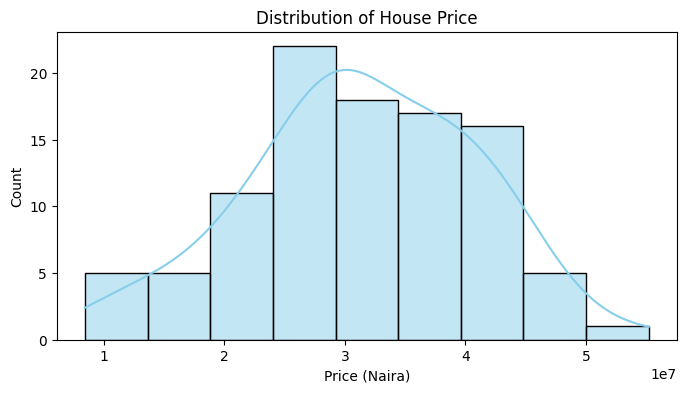

Before filling:
Area_sqft    0
Bedrooms     0
Bathrooms    1
Age_years    1
Location     0
Price        0
dtype: int64

After filling:
Area_sqft    0
Bedrooms     0
Bathrooms    0
Age_years    0
Location     0
Price        0
dtype: int64

After One-Hot Encoding:
   Area_sqft  Bedrooms  Bathrooms  Age_years     Price  Location_Ilorin  \
0       1460         3        3.0        7.0  37686420            False   
1       1894         3        2.0       26.0  37917884            False   
2       1730         1        2.0       26.0  17609720             True   
3       1695         3        1.0       33.0  26276771            False   
4       2238         3        2.0       20.0  40832009            False   

   Location_Lagos  
0            True  
1            True  
2           False  
3           False  
4            True  
['Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_years', 'Price', 'Location_Ilorin', 'Location_Lagos']


In [3]:
# 1. Distribution of target variable (Price)
plt.figure(figsize=(8,4))
sns.histplot(df['Price'], kde=True, color='skyblue')
plt.title('Distribution of House Price')
plt.xlabel('Price (Naira)')
plt.show()

# 2. Handle missing values - fill with median
print("Before filling:")
print(df.isnull().sum())

df['Age_years'] = df['Age_years'].fillna(df['Age_years'].median())
df['Bathrooms'] = df['Bathrooms'].fillna(df['Bathrooms'].median())

print("\nAfter filling:")
print(df.isnull().sum())

# 3. One-Hot Encoding for Location
df_encoded = pd.get_dummies(df, columns=['Location'], drop_first=True)
print("\nAfter One-Hot Encoding:")
print(df_encoded.head())
print(df_encoded.columns.tolist())

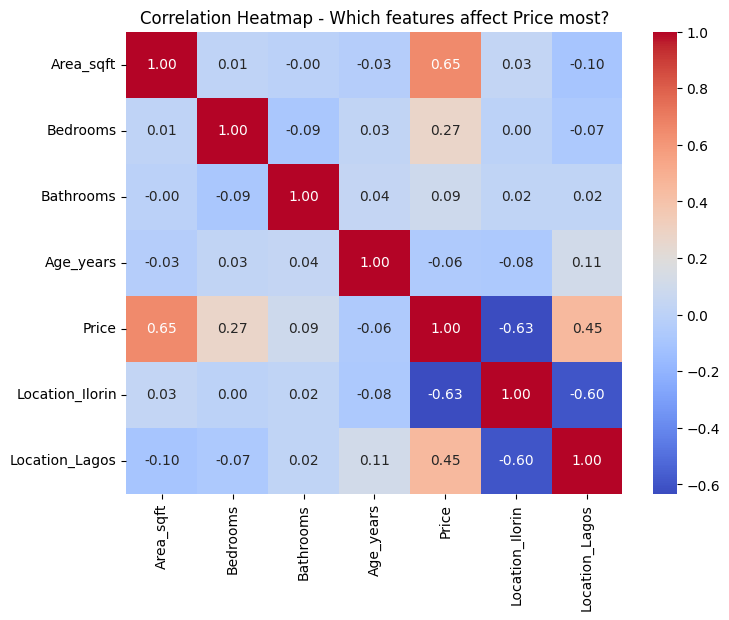

Train shape: (80, 6)
Test shape: (20, 6)

MSE: 1,771,256,473,779.18
RMSE: 1,330,885.60
R2 Score: 0.9665

This means our model explains 96.6% of the variation in house prices.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df_encoded.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Which features affect Price most?')
plt.show()

# 2. Define X and y
X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']

# 3. Train/Test split 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

# 4. Train Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and Evaluate
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nMSE: {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")
print(f"\nThis means our model explains {r2*100:.1f}% of the variation in house prices.")

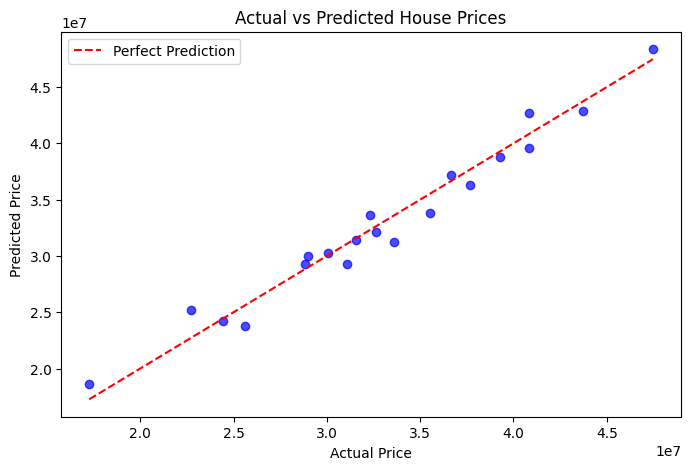

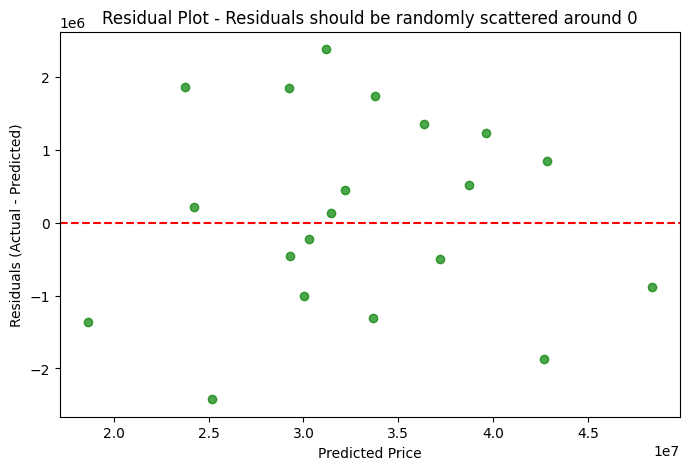

           Feature   Coefficient
4  Location_Ilorin -1.029821e+07
5   Location_Lagos  4.516278e+06
1         Bedrooms  1.878082e+06
2        Bathrooms  1.562943e+06
3        Age_years -1.009142e+05
0        Area_sqft  7.903327e+03

Interpretation: Area_sqft has the highest impact. Location_Lagos increases price, Age_years decreases price.


/tmp/ipykernel_1887/2781313833.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='viridis')


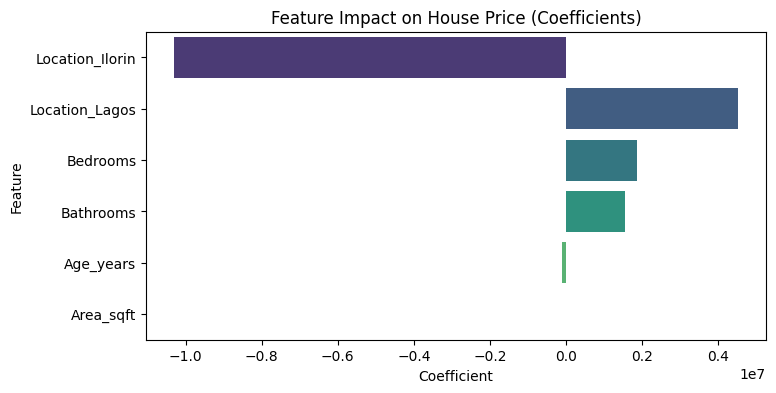

In [5]:
# 1. Scatter Plot: Actual vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.show()

# 2. Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, color='green', alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot - Residuals should be randomly scattered around 0')
plt.show()

# 3. Coefficient Analysis
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
coef_df = coef_df.sort_values(by='Coefficient', key=abs, ascending=False)
print(coef_df)
print("\nInterpretation: Area_sqft has the highest impact. Location_Lagos increases price, Age_years decreases price.")

plt.figure(figsize=(8,4))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='viridis')
plt.title('Feature Impact on House Price (Coefficients)')
plt.show()

In [6]:
from sklearn.linear_model import Ridge, Lasso

# Ridge and Lasso
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=1.0)

ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

print("Model Comparison:")
print(f"Linear Regression R2: {r2_score(y_test, model.predict(X_test)):.4f}")
print(f"Ridge Regression R2: {r2_score(y_test, ridge.predict(X_test)):.4f}")
print(f"Lasso Regression R2: {r2_score(y_test, lasso.predict(X_test)):.4f}")

# Conclusion text
print("\nConclusion: All three models perform similarly because our dataset is simple and clean. Linear Regression is best here because it is simplest and has highest R2.")

Model Comparison:
Linear Regression R2: 0.9665
Ridge Regression R2: 0.9651
Lasso Regression R2: 0.9665

Conclusion: All three models perform similarly because our dataset is simple and clean. Linear Regression is best here because it is simplest and has highest R2.


## Conclusion

In this task, I built a Linear Regression model to predict house prices using area, number of bedrooms, number of bathrooms, age of the house, and location.

Key findings:
- The model achieved an R² score of 0.9665, which means it explains 96.6% of the variation in house prices.
- The Root Mean Squared Error (RMSE) was 1,330,885, which means the predictions were on average about 1.3 million Naira away from the actual prices.
- Area in square feet was the most strongly correlated feature with price, with a correlation of 0.65.
- The residuals were randomly scattered around zero, which indicates that the model does not have a systematic error.
- Ridge Regression (R² = 0.9651) and Lasso Regression (R² = 0.9665) produced similar results. Therefore, simple Linear Regression was selected as the best model because of its simplicity and strong performance.